Product Recommendation Model

The goal here is to predict the product category that a customer buys

Setup

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, f1_score, log_loss, confusion_matrix

sns.set_style("whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)

Loading the data

In [3]:
from google.colab import files
uploaded = files.upload()

Saving customer_social_profiles - customer_social_profiles.csv to customer_social_profiles - customer_social_profiles.csv
Saving customer_transactions - customer_transactions.csv to customer_transactions - customer_transactions.csv


Config

In [6]:
import glob

SOCIAL_PATH = glob.glob("customer_social_profiles*.csv")[0]
TRANS_PATH = glob.glob("customer_transactions*.csv")[0]
TARGET = "product_category"

print(SOCIAL_PATH)
print(TRANS_PATH)

customer_social_profiles - customer_social_profiles.csv
customer_transactions - customer_transactions.csv


In [7]:
social = pd.read_csv(SOCIAL_PATH, sep=None, engine="python")
trans = pd.read_csv(TRANS_PATH, sep=None, engine="python")

In [8]:
social.head()

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [9]:
trans.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [38]:
for name, df in [("social", social), ("transactions", trans)]:
    print(f"{name}")
    print("shape:", df.shape)
    print(df.dtypes)
    print("nulls:")
    print(df.isna().sum())
    print("exact duplicate rows:", df.duplicated().sum())
    print()

social
shape: (150, 6)
customer_id_new             object
social_media_platform       object
engagement_score             int64
purchase_interest_score    float64
review_sentiment            object
customer_id                  int64
dtype: object
nulls:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
customer_id                0
dtype: int64
exact duplicate rows: 0

transactions
shape: (150, 7)
customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[ns]
product_category              object
customer_rating              float64
customer_id                    int64
dtype: object
nulls:
customer_id_legacy    0
transaction_id        0
purchase_amount       0
purchase_date         0
product_category      0
customer_rating       0
customer_id           0
dtype: int64
exact duplicate rows: 0



Cleaning the data

In [11]:
#Social profiles
print("social rows before:", len(social))
social = social.drop_duplicates()
print("social rows after dropping exact duplicates:", len(social))

# 'A178' -> 178
social["customer_id"] = social["customer_id_new"].str.replace("A", "", regex=False).astype(int)

#Transactions
trans["customer_id"] = trans["customer_id_legacy"].astype(int)
trans["purchase_date"] = pd.to_datetime(trans["purchase_date"])
print("duplicate transaction_ids:", trans["transaction_id"].duplicated().sum())

social rows before: 155
social rows after dropping exact duplicates: 150
duplicate transaction_ids: 0


In [12]:
# Missing ratings
print("missing ratings before:", trans["customer_rating"].isna().sum())
trans["customer_rating"] = trans["customer_rating"].fillna(trans["customer_rating"].median())
print("missing ratings after:", trans["customer_rating"].isna().sum())

missing ratings before: 10
missing ratings after: 0


We removed 5 duplicate rows to get 150 rows. We even had to change the way the customer IDs were stored in 2 files to have a common integer, by removing the letter from the customer_id. On the other hand transactions had no duplicates but 10 customer rating values were missing so as a result we filled them with a median since it is not affected by extreme values and lastly purchase_date was converted to a date type.

Merging

In [13]:
print("social rows per customer:")
print(social["customer_id"].value_counts().describe())

social rows per customer:
count    84.000000
mean      1.785714
std       1.006861
min       1.000000
25%       1.000000
50%       1.000000
75%       2.000000
max       6.000000
Name: count, dtype: float64


In [14]:
def mode_first(s):
    return s.mode().iloc[0]

social_agg = social.groupby("customer_id").agg(
    avg_engagement=("engagement_score", "mean"),
    avg_purchase_interest=("purchase_interest_score", "mean"),
    n_social_profiles=("social_media_platform", "count"),
    top_platform=("social_media_platform", mode_first),
    top_sentiment=("review_sentiment", mode_first),
).reset_index()

print("customers in social data:", len(social_agg))
social_agg.head()

customers in social data: 84


,customer_id,avg_engagement,avg_purchase_interest,n_social_profiles,top_platform,top_sentiment
0,100,77.000000,4.400000,2,Instagram,Negative
1,101,68.000000,1.000000,1,Twitter,Neutral
2,102,51.000000,4.800000,1,LinkedIn,Neutral
3,103,64.333333,2.866667,3,Instagram,Positive
4,104,83.000000,2.933333,3,Twitter,Negative


In [15]:
merged = trans.merge(social_agg, on="customer_id", how="left",
                     validate="m:1", indicator=True)

print("transactions:", len(trans))
print("merged rows:", len(merged), "(should be equal: no rows gained or lost)")
print(merged["_merge"].value_counts())

transactions: 150
merged rows: 150 (should be equal: no rows gained or lost)
_merge
both          117
left_only      33
right_only      0
Name: count, dtype: int64


In [16]:
# Customers with no social profile get neutral fill values
social_cols_num = ["avg_engagement", "avg_purchase_interest"]
print("nulls after merge:")
print(merged.isna().sum()[lambda s: s > 0])

merged[social_cols_num] = merged[social_cols_num].fillna(merged[social_cols_num].median())
merged["n_social_profiles"] = merged["n_social_profiles"].fillna(0)
merged["top_platform"] = merged["top_platform"].fillna("Unknown")
merged["top_sentiment"] = merged["top_sentiment"].fillna("Unknown")
merged = merged.drop(columns="_merge")

print("nulls left:", merged.isna().sum().sum())

nulls after merge:
avg_engagement           33
avg_purchase_interest    33
n_social_profiles        33
top_platform             33
top_sentiment            33
dtype: int64
nulls left: 0


We aggregated bcz social data has multiple rows for each customer and a customer can have profiles on various platforms. To avoid duplication of transactions, we decided to summarise the social data down to one row per customer.

The total number of rows is 150, which is the same as the transactions. For 117 transactions, there was a match with a social profile and for 33, there was no match of a social profile and the numeric social features for the 33 transactions were filled with the median.

EDA

In [17]:
merged.describe(include="all")

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,avg_engagement,avg_purchase_interest,n_social_profiles,top_platform,top_sentiment
count,150.000000,150.000000,150.000000,150,150,150.000000,150.000000,150.000000,150.000000,150.000000,150,150
unique,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,6,4
top,NaN,NaN,NaN,NaN,Sports,NaN,NaN,NaN,NaN,NaN,Unknown,Positive
freq,NaN,NaN,NaN,NaN,35,NaN,NaN,NaN,NaN,NaN,33,44
mean,148.760000,1075.500000,280.780000,2024-03-15 12:00:00,NaN,2.986000,148.760000,74.780556,3.089556,1.420000,NaN,NaN
min,100.000000,1001.000000,51.000000,2024-01-01 00:00:00,NaN,1.000000,100.000000,50.000000,1.000000,0.000000,NaN,NaN
25%,121.250000,1038.250000,179.000000,2024-02-07 06:00:00,NaN,2.100000,121.250000,68.312500,2.733333,1.000000,NaN,NaN
50%,150.500000,1075.500000,274.000000,2024-03-15 12:00:00,NaN,3.000000,150.500000,77.000000,3.133333,1.000000,NaN,NaN
75%,174.750000,1112.750000,388.500000,2024-04-21 18:00:00,NaN,4.000000,174.750000,81.000000,3.600000,2.000000,NaN,NaN
max,199.000000,1150.000000,495.000000,2024-05-29 00:00:00,NaN,5.000000,199.000000,99.000000,4.800000,4.000000,NaN,NaN


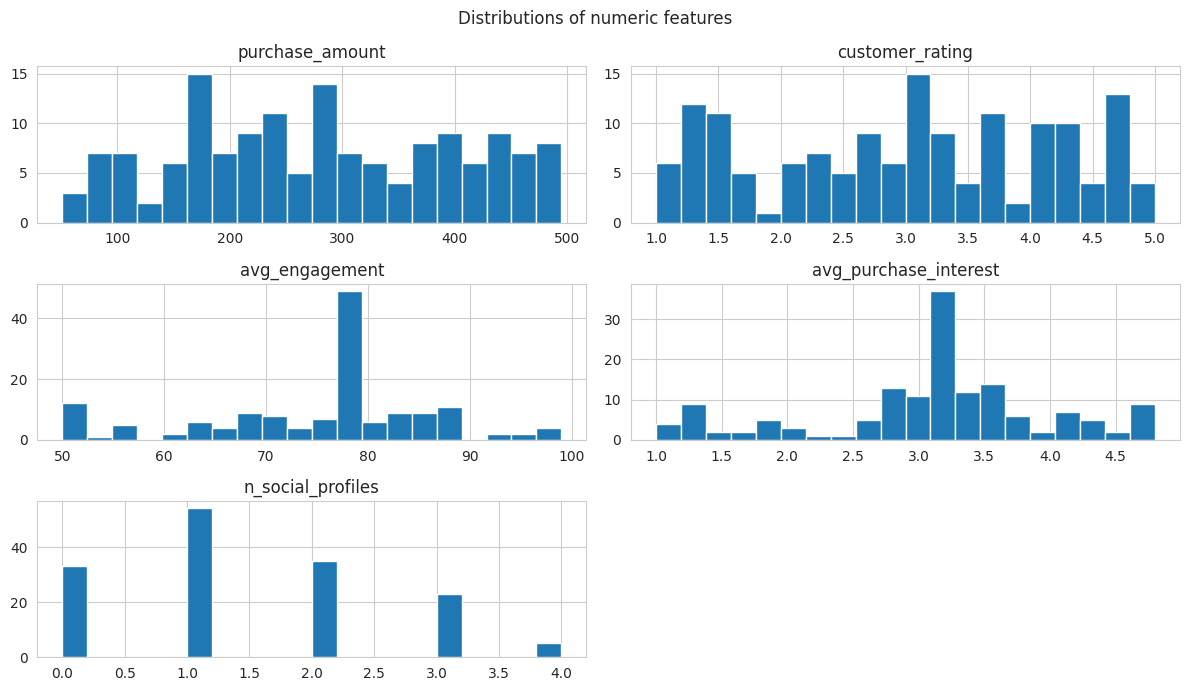

In [18]:
num_cols = ["purchase_amount", "customer_rating", "avg_engagement",
            "avg_purchase_interest", "n_social_profiles"]
merged[num_cols].hist(figsize=(12, 7), bins=20)
plt.suptitle("Distributions of numeric features")
plt.tight_layout()
plt.show()

purchase_amount is spread fairly evenly between about 50 and 500 with no strong skew. customer_rating covers the whole 1 to 5 range with no single peak with a mean of about 3.0. The tall spikes in avg_engagement  and avg_purchase_interest  are not real customer behaviour because they come from filling the 33 customers without a social profile with the median. n_social_profiles shows the same group as the bar at 0, and most customers have 1 or 2 profiles.

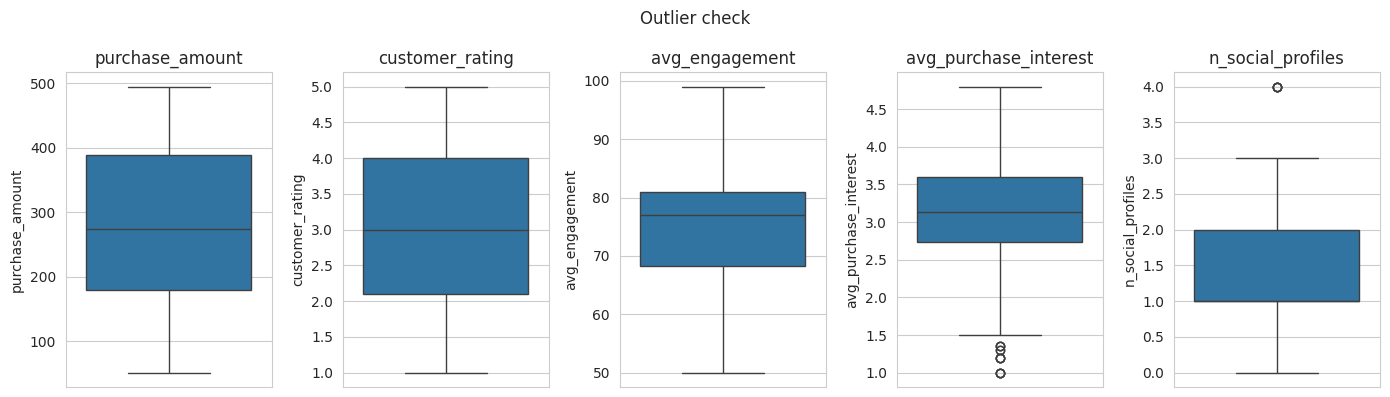

In [19]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=merged[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Outlier check")
plt.tight_layout()
plt.show()

There are no outliers for purchase_amount, customer_rating and avg_engagement however avg_purchase_interest has a few low values  and n_social_profiles has one high value. These are values within the scoring scales and are reasonable, valid customers, not data errors, and so we kept them.

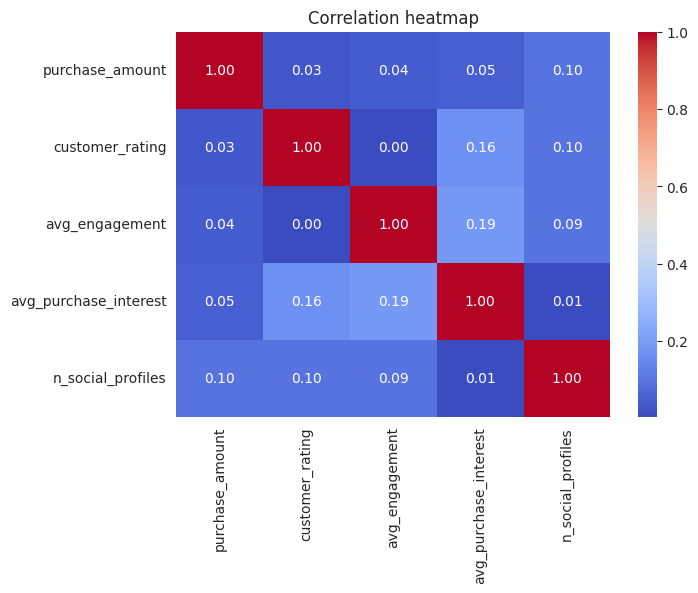

In [20]:
plt.figure(figsize=(7, 5))
sns.heatmap(merged[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

All correlations between the numeric features are weak. The best performing are avg_engagement and avg_purchase_interest, customer_rating and avg_purchase_interest, and purchase_amount is almost unrelated to everything (0.03 to 0.10). No multicollinearity issues exist, but that also means that there is not a lot of linear signal and that means that predicting the product will be difficult.

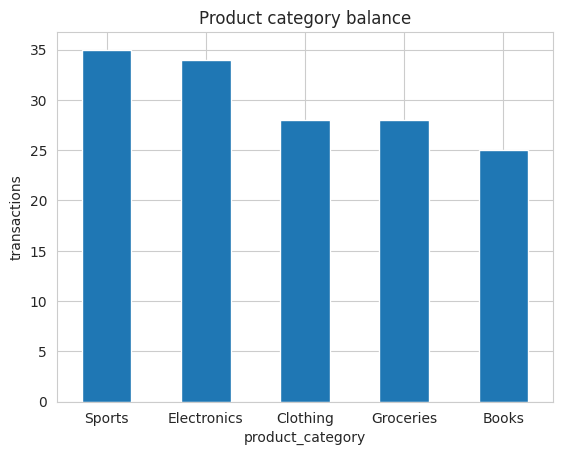

In [21]:
merged[TARGET].value_counts().plot(kind="bar")
plt.title("Product category balance")
plt.ylabel("transactions")
plt.xticks(rotation=0)
plt.show()

The five categories are fairly balanced with Sports at 35, Electronics at 34, Clothing at 28, Groceries at 28 and Books at 25. The largest class is only about 23% of the data, so there is no need for resampling and accuracy is a meaningful metric. Random guessing would score about 20%.

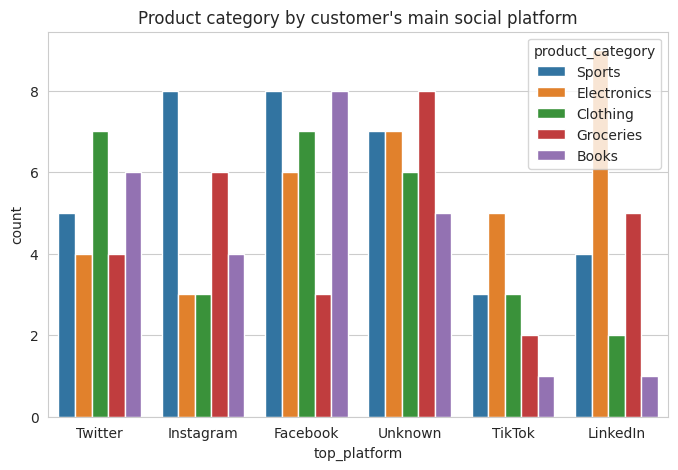

In [22]:
plt.figure(figsize=(8, 5))
sns.countplot(data=merged, x="top_platform", hue=TARGET)
plt.title("Product category by customer's main social platform")
plt.show()

As it is being shown no platform is dominating one product. For example Instagram customers lean more towards sports while tiktok customers lean more towards electronics. The unkown group on the other hand is evenly spread across all products

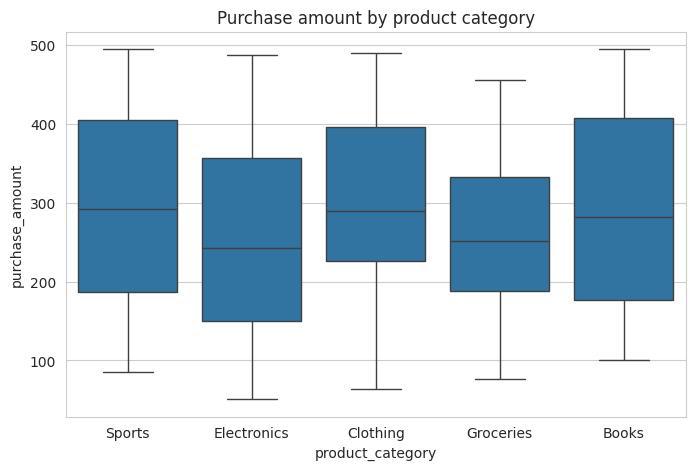

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=merged, x=TARGET, y="purchase_amount")
plt.title("Purchase amount by product category")
plt.show()

The median purchases amount in the various categories is approximately the same in the range of 240-290 and there is a significant overlap between the boxes in the various categories. Electronics and Groceries have slightly lower medians, and Groceries has a narrower range, but the amount alone does not separate the categories.

Feature Engineering

In [24]:
# Date features
merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_weekday"] = merged["purchase_date"].dt.dayofweek
merged["is_weekend"] = (merged["purchase_weekday"] >= 5).astype(int)

# Customer-level behaviour
merged["cust_avg_spend"] = merged.groupby("customer_id")["purchase_amount"].transform("mean")
merged["cust_purchase_count"] = merged.groupby("customer_id")["transaction_id"].transform("count")

# Social interaction + spend level
merged["interest_x_engagement"] = merged["avg_engagement"] * merged["avg_purchase_interest"]
merged["high_value_purchase"] = (merged["purchase_amount"] > merged["purchase_amount"].median()).astype(int)

merged.to_csv("data/merged_dataset.csv", index=False)
merged.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,avg_engagement,avg_purchase_interest,n_social_profiles,top_platform,top_sentiment,purchase_month,purchase_weekday,is_weekend,cust_avg_spend,cust_purchase_count,interest_x_engagement,high_value_purchase
0,151,1001,408,2024-01-01,Sports,2.3,151,71.666667,2.166667,3.0,Twitter,Neutral,1,0,0,408.0,1,155.277778,1
1,192,1002,332,2024-01-02,Electronics,4.2,192,60.000000,4.300000,1.0,Instagram,Positive,1,1,0,411.5,2,258.000000,1
2,114,1003,442,2024-01-03,Electronics,2.1,114,87.000000,4.800000,1.0,Facebook,Negative,1,2,0,258.5,4,417.600000,1
3,171,1004,256,2024-01-04,Clothing,2.8,171,77.000000,3.133333,0.0,Unknown,Unknown,1,3,0,181.0,3,241.266667,0
4,160,1005,64,2024-01-05,Clothing,1.3,160,72.666667,2.500000,3.0,Instagram,Neutral,1,4,0,64.0,1,181.666667,0


X and Y

In [25]:
drop_cols = ["customer_id_legacy", "transaction_id", "purchase_date", "customer_id", TARGET]
X = merged.drop(columns=drop_cols)
X = pd.get_dummies(X, columns=["top_platform", "top_sentiment"], dtype=int)

le = LabelEncoder()
y = le.fit_transform(merged[TARGET])
print("X shape:", X.shape)
print("classes:", list(le.classes_))

X shape: (150, 22)
classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, "test:", X_test.shape)

train: (120, 22) test: (30, 22)


Random Forest

In [27]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("F1 (weighted):", round(f1_score(y_test, rf_pred, average="weighted"), 3))
print("Log loss:", round(log_loss(y_test, rf_proba, labels=rf.classes_), 3))
print(classification_report(y_test, rf_pred, target_names=le.classes_))

Accuracy: 0.167
F1 (weighted): 0.14
Log loss: 1.886
              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       0.18      0.33      0.24         6
 Electronics       0.25      0.29      0.27         7
   Groceries       0.17      0.20      0.18         5
      Sports       0.00      0.00      0.00         7

    accuracy                           0.17        30
   macro avg       0.12      0.16      0.14        30
weighted avg       0.12      0.17      0.14        30



Logistic Regression

In [28]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)

print("Accuracy:", round(accuracy_score(y_test, lr_pred), 3))
print("F1 (weighted):", round(f1_score(y_test, lr_pred, average="weighted"), 3))
print("Log loss:", round(log_loss(y_test, lr_proba, labels=le.transform(le.classes_)), 3))
print(classification_report(y_test, lr_pred, target_names=le.classes_))

Accuracy: 0.133
F1 (weighted): 0.125
Log loss: 2.914
              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       0.33      0.33      0.33         6
 Electronics       0.00      0.00      0.00         7
   Groceries       0.00      0.00      0.00         5
      Sports       0.22      0.29      0.25         7

    accuracy                           0.13        30
   macro avg       0.11      0.12      0.12        30
weighted avg       0.12      0.13      0.12        30



Comparing the models

In [29]:
results = pd.DataFrame({
    "Random Forest": [accuracy_score(y_test, rf_pred), f1_score(y_test, rf_pred, average="weighted"), log_loss(y_test, rf_proba)],
    "Logistic Regression": [accuracy_score(y_test, lr_pred), f1_score(y_test, lr_pred, average="weighted"), log_loss(y_test, lr_proba)],
}, index=["Accuracy", "F1 (weighted)", "Log loss"]).T.round(3)

baseline = 1 / len(le.classes_)
print(f"Random-guess baseline accuracy: {baseline:.2f}")
results

Random-guess baseline accuracy: 0.20


,Accuracy,F1 (weighted),Log loss
Random Forest,0.167,0.140,1.886
Logistic Regression,0.133,0.125,2.914


In [31]:
# The test set is only 30 rows, so a single split is noisy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in [("Random Forest", rf), ("Logistic Regression", lr)]:
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    print(name, "fold scores:", scores.round(3))
    print(f"  mean: {scores.mean():.3f}, std: {scores.std():.3f}")

Random Forest fold scores: [0.3   0.333 0.267 0.133 0.333]
  mean: 0.273, std: 0.074
Logistic Regression fold scores: [0.167 0.2   0.2   0.2   0.333]
  mean: 0.220, std: 0.058


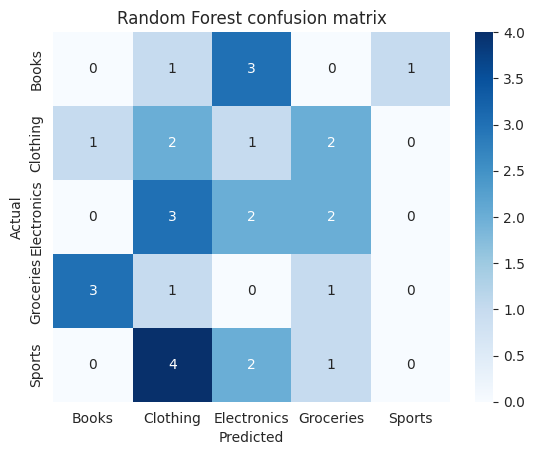

In [32]:
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Random Forest confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

The model got only 5 of 30 test predictions right. It never correctly predicted Sports or Books, and its mistakes are spread across all categories with no clear pattern. This shows the model is not learning to tell the products apart.


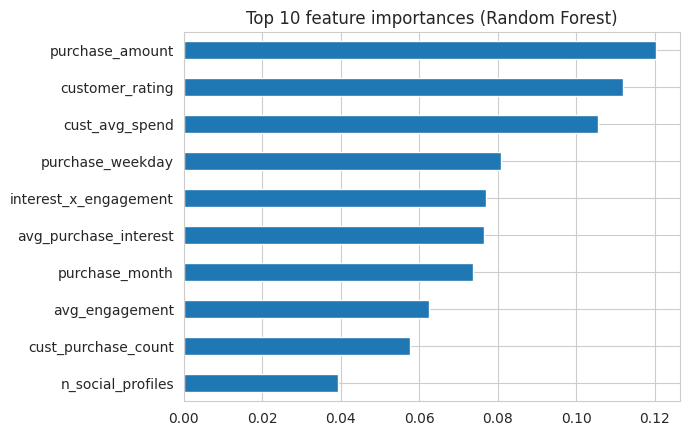

In [33]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.plot(kind="barh")
plt.title("Top 10 feature importances (Random Forest)")
plt.gca().invert_yaxis()
plt.show()

No single feature stands out, since all of them have similar importance. The top three purchase_amount, customer_rating, cust_avg_spend come from the transaction data, while the social media features rank lower. Because the overall signal is weak, these rankings should not be over-interpreted.

Saving the model

In [34]:
best_name = results["F1 (weighted)"].idxmax()
best_model = {"Random Forest": rf, "Logistic Regression": lr}[best_name]
print("Saving:", best_name)

joblib.dump({"model": best_model, "label_encoder": le, "columns": X.columns.tolist()},
            "models/product_model.pkl")

# Feature table the CLI looks customers up in
feature_table = X.copy()
feature_table.insert(0, "customer_id", merged["customer_id"].values)
feature_table.insert(1, "purchase_date", merged["purchase_date"].values)
feature_table.to_csv("data/model_features.csv", index=False)

Saving: Random Forest


In [35]:
def predict_product(customer_id):
    # Takes a customer id and returns the predicted product category
    bundle = joblib.load("models/product_model.pkl")
    feats = pd.read_csv("data/model_features.csv")
    rows = feats[feats["customer_id"] == int(customer_id)]
    if rows.empty:
        raise ValueError(f"Unknown customer id: {customer_id}")
    latest = rows.sort_values("purchase_date").iloc[[-1]]
    pred = bundle["model"].predict(latest[bundle["columns"]])
    return bundle["label_encoder"].inverse_transform(pred)[0]

print(predict_product(151))

Clothing


In [37]:
from google.colab import files
for f in ["models/product_model.pkl", "data/merged_dataset.csv", "data/model_features.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>